In [ ]:
# coding: utf-8
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score
import matplotlib.pyplot as plt
import umap.umap_ as umap
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import cosine_similarity

# load data
df = pd.read_csv("/Users/liqun/scMutraceProject/Data/cellLine/gCSM/gCellSNPMatrix.step3.1_excludeControlSites.csv", index_col=0)

# 'Mut' -> 1, 'WT' -> 0, 'NoCall' -> -1
value_map = {'Mut': 1, 'WT': 0, 'NoCall': -1}
encoded_df = df.map(lambda x: value_map[x])

# transform to sparse matrix
rows, cols = np.where(encoded_df != 0)
data = encoded_df.values[rows, cols]
sparse_mtx = sparse.coo_matrix((data, (rows, cols)), 
                             shape=encoded_df.shape,
                             dtype=np.int8).tocsr()
print("Mutations X Cells: ", sparse_mtx.shape)

Mutations X Cells:  (1810, 3154)


In [4]:
# cell ids
cell_ids = encoded_df.columns
# mutation ids
mutation_ids = encoded_df.index
# calculate the number of mutations per cell
num_mutations_per_cell = np.array((sparse_mtx == 1).sum(axis=0)).flatten()
# calculate the number of cells per mutation
num_Mutcells_per_mutation = np.array((sparse_mtx == 1).sum(axis=1)).flatten()

print("cell ids: ", cell_ids.shape, cell_ids)
print("mutation ids: ", mutation_ids.shape, mutation_ids)
print("Number of mutations per cell: ", num_mutations_per_cell.shape, num_mutations_per_cell)
print("Number of mut cells per mutation: ", num_Mutcells_per_mutation.shape, num_Mutcells_per_mutation)

cell ids:  (3154,) Index(['SNU601_AAACGAAAGGGAGATA', 'SNU601_AAACGAACACAAACGG',
       'SNU601_AAACGAAGTACGCCCA', 'SNU601_AAACGAAGTGCAACAG',
       'SNU601_AAACTCGAGAAATGGG', 'SNU601_AAACTCGAGCGTAGCA',
       'SNU601_AAACTCGGTCAGTGTT', 'SNU601_AAACTCGGTTGTGACT',
       'SNU601_AAACTCGGTTTCAGCA', 'SNU601_AAACTCGTCACTGATG',
       ...
       'SNU601_TTTGGTTGTAGAATAC', 'SNU601_TTTGGTTTCGGTCTCT',
       'SNU601_TTTGGTTTCGTTCCGT', 'SNU601_TTTGTGTAGAACTAAC',
       'SNU601_TTTGTGTAGACGCCCT', 'SNU601_TTTGTGTAGGGTCTGA',
       'SNU601_TTTGTGTAGTCCAGAG', 'SNU601_TTTGTGTCACGCTCAG',
       'SNU601_TTTGTGTCAGTAACGG', 'SNU601_TTTGTGTTCATTCGGA'],
      dtype='object', length=3154)
mutation ids:  (1810,) Index(['chr10_100345948_T_A', 'chr10_100979943_G_A', 'chr10_101124154_C_T',
       'chr10_101817742_G_A', 'chr10_102394462_A_G', 'chr10_102710947_G_A',
       'chr10_102715392_A_G', 'chr10_103079089_G_A', 'chr10_103184840_A_G',
       'chr10_109967494_C_G',
       ...
       'chrX_43716918_G_C', 'chr

In [5]:
# ensure the data types are correct
num_Mutcells_per_mutation = num_Mutcells_per_mutation.astype(int)
num_mutations_per_cell = num_mutations_per_cell.astype(int)

# define thresholds for filtering
# 10th percentile of mutations per cell and cells per mutation
# to avoid too many zeros
min_cells = max(5, np.percentile(num_Mutcells_per_mutation, 10))
min_mutations = max(5, np.percentile(num_mutations_per_cell, 10))

# create masks for filtering
row_mask = num_Mutcells_per_mutation >= min_cells
col_mask = num_mutations_per_cell >= min_mutations

# filter the sparse matrix
filtered_sparse_mtx = sparse_mtx[row_mask, :][:, col_mask]
filtered_mutation_ids = mutation_ids[row_mask]
filtered_cell_ids = cell_ids[col_mask]

print("Filtered Mutations X Cells: ", filtered_sparse_mtx.shape)
print("Filtered cell ids: ", filtered_cell_ids.shape, filtered_cell_ids)
print("Filtered mutation ids: ", filtered_mutation_ids.shape, filtered_mutation_ids)

Filtered Mutations X Cells:  (1738, 2875)
Filtered cell ids:  (2875,) Index(['SNU601_AAACGAAAGGGAGATA', 'SNU601_AAACGAACACAAACGG',
       'SNU601_AAACGAAGTACGCCCA', 'SNU601_AAACGAAGTGCAACAG',
       'SNU601_AAACTCGAGAAATGGG', 'SNU601_AAACTCGAGCGTAGCA',
       'SNU601_AAACTCGGTCAGTGTT', 'SNU601_AAACTCGGTTGTGACT',
       'SNU601_AAACTCGGTTTCAGCA', 'SNU601_AAACTCGTCACTGATG',
       ...
       'SNU601_TTTGGTTCAGGATGTG', 'SNU601_TTTGGTTGTAGAATAC',
       'SNU601_TTTGGTTTCGGTCTCT', 'SNU601_TTTGGTTTCGTTCCGT',
       'SNU601_TTTGTGTAGAACTAAC', 'SNU601_TTTGTGTAGACGCCCT',
       'SNU601_TTTGTGTAGGGTCTGA', 'SNU601_TTTGTGTAGTCCAGAG',
       'SNU601_TTTGTGTCACGCTCAG', 'SNU601_TTTGTGTTCATTCGGA'],
      dtype='object', length=2875)
Filtered mutation ids:  (1738,) Index(['chr10_100345948_T_A', 'chr10_100979943_G_A', 'chr10_101124154_C_T',
       'chr10_101817742_G_A', 'chr10_102394462_A_G', 'chr10_102710947_G_A',
       'chr10_102715392_A_G', 'chr10_103184840_A_G', 'chr10_109967494_C_G',
       'chr10

In [ ]:
def select_best_nk(nmf_input, max_n=8, max_k=20, min_diff=0.05):
    best_n, best_k, best_score = None, None, -1
    scores = {}

    for n in range(2, max_n + 1):
        nmf = NMF(n_components=n, init='nndsvd', random_state=42)
        W = nmf.fit_transform(nmf_input.T)

        k_scores = []
        for k in range(2, min(n + 1, max_k + 1)):
            kmeans = KMeans(n_clusters=k, random_state=42)
            labels = kmeans.fit_predict(W)
            score = silhouette_score(W, labels)
            k_scores.append((k, score))

        k_scores.sort(key=lambda x: x[0])

        filtered_k_scores = []
        for i, (k, score) in enumerate(k_scores):
            if i == 0:
                filtered_k_scores.append((k, 0))
            if score - k_scores[i - 1][1] >= min_diff:  
                filtered_k_scores.append((k, score))

        if filtered_k_scores:
            best_k_for_n, best_score_for_n = max(filtered_k_scores, key=lambda x: x[1])
            scores[n] = filtered_k_scores

            if best_score_for_n > best_score:
                best_n, best_k, best_score = n, best_k_for_n, best_score_for_n

    return best_n, best_k, best_score


NMF W shape:  (2875, 6)
NMF H shape:  (6, 1738)


/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


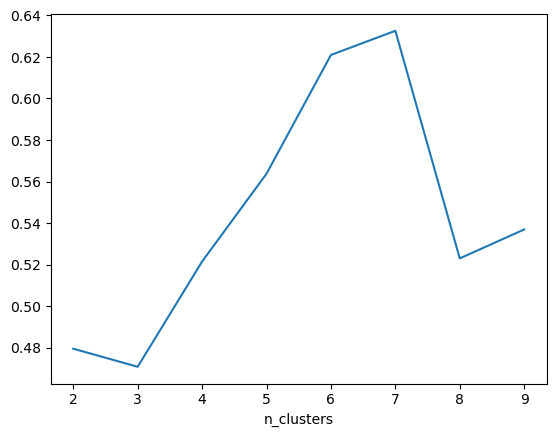

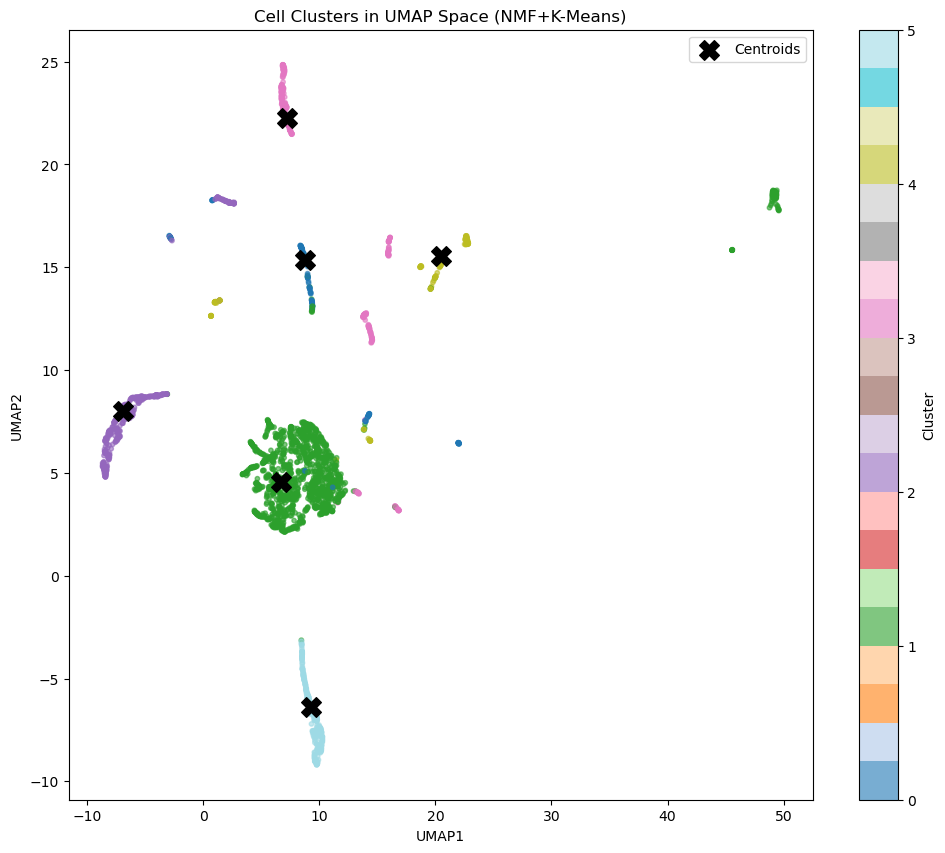

In [ ]:
# NFM
nmf_input = filtered_sparse_mtx.copy()
# -1→0, 0→1, 1→2
nmf_input.data = nmf_input.data + 1


best_n, best_k, best_score = select_best_nk(nmf_input, max_n=8, max_k=20, min_diff=0.05)


# NMF降维
n_components = best_n
best_k = best_k

nmf = NMF(n_components=n_components, 
          init='nndsvd', 
          random_state=42,
          max_iter = 1000)
W = nmf.fit_transform(nmf_input.T)
H = nmf.components_
print("NMF W shape: ", W.shape)
print("NMF H shape: ", H.shape)


best_k = best_k
# select best K
scores = []
for k in range(2, best_k + 4):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(W)
    scores.append(silhouette_score(W, labels))
plt.plot(range(2, best_k + 4), scores); plt.xlabel('n_clusters')

# K-Means

kmeans = KMeans(n_clusters = best_k, random_state=42)
clusters = kmeans.fit_predict(W)

reducer = umap.UMAP(metric='cosine', random_state=42)
embedding = reducer.fit_transform(W)



plt.figure(figsize=(12, 10))
sc = plt.scatter(embedding[:, 0], embedding[:, 1],
                c=clusters, 
                s=10,
                cmap='tab20',
                alpha=0.6)
plt.colorbar(sc, label='Cluster')
plt.title("Cell Clusters in UMAP Space (NMF+K-Means)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# 标记聚类中心
centers_umap = reducer.transform(kmeans.cluster_centers_)
plt.scatter(centers_umap[:, 0], centers_umap[:, 1],
           marker='X', s=200, c='black', label='Centroids')
plt.legend()
plt.show()

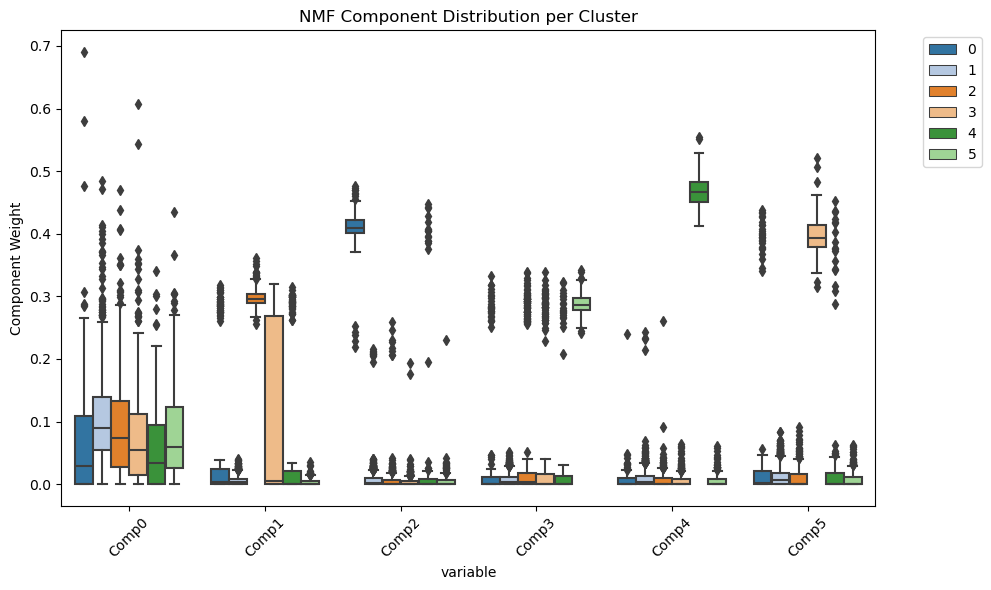

In [8]:
cluster_components = pd.DataFrame(W, 
                                columns=[f"Comp{i}" for i in range(n_components)])
cluster_components['Cluster'] = clusters

plt.figure(figsize=(10, 6))
sns.boxplot(data=cluster_components.melt(id_vars='Cluster'),
            x='variable', y='value', hue='Cluster',
            palette='tab20')
plt.title("NMF Component Distribution per Cluster")
plt.xticks(rotation=45)
plt.ylabel("Component Weight")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

In [9]:
# count each cluster number
cluster_counts = pd.Series(clusters).value_counts()
print("Cluster counts: ", cluster_counts)

Cluster counts:  1    1575
2     415
3     295
5     253
0     170
4     167
Name: count, dtype: int64


In [10]:
cluster_centers = kmeans.cluster_centers_
top_features = {}
top_n = 10
for cluster_id in range(best_k):
    # 计算该cluster中心对各组件的权重
    cluster_weights = cluster_centers[cluster_id]
    
    # 计算特征对cluster的贡献 = H.T × cluster_weights
    feature_contributions = H.T @ cluster_weights  # 矩阵乘法
    
    # 获取贡献最大的top_n个特征
    top_indices = np.argsort(feature_contributions)[-top_n:][::-1]
    #top_features[cluster_id] = [
    #    (idx, feature_names[idx], feature_contributions[idx]) 
    #    for idx in top_indices
    #]
    top_features[cluster_id] = [
        (idx, filtered_mutation_ids[idx], feature_contributions[idx]) 
        for idx in top_indices
    ]
print(top_features)

{0: [(1321, 'chr6_138773705_G_T', 2.0168266105306056), (1320, 'chr6_138773704_G_T', 1.8931990770817002), (566, 'chr17_4483685_G_A', 0.468526183567874), (240, 'chr12_31732990_C_T', 0.3336020215938014), (601, 'chr17_8249289_A_G', 0.3304091001540072), (711, 'chr19_54162454_T_C', 0.3240023490299242), (928, 'chr20_49219331_A_C', 0.25259091872876305), (767, 'chr1_159799037_T_C', 0.22250255826167759), (58, 'chr10_72626164_T_G', 0.21760631978677492), (761, 'chr1_155227573_G_A', 0.21105711380621328)], 1: [(1479, 'chr7_23273214_T_C', 0.28758662931731355), (928, 'chr20_49219331_A_C', 0.2221972526306319), (927, 'chr20_45881074_C_T', 0.2173570856598099), (1315, 'chr6_136594160_T_C', 0.20198504761013508), (761, 'chr1_155227573_G_A', 0.17856448705402547), (240, 'chr12_31732990_C_T', 0.16520114679076595), (759, 'chr1_154983165_A_G', 0.16043193527526672), (1566, 'chr8_125696990_G_A', 0.15710749377742847), (562, 'chr17_39980663_A_T', 0.15185529095190947), (1296, 'chr6_106103868_T_C', 0.14010429427908377

In [11]:
top_features

{0: [(1321, 'chr6_138773705_G_T', 2.0168266105306056),
  (1320, 'chr6_138773704_G_T', 1.8931990770817002),
  (566, 'chr17_4483685_G_A', 0.468526183567874),
  (240, 'chr12_31732990_C_T', 0.3336020215938014),
  (601, 'chr17_8249289_A_G', 0.3304091001540072),
  (711, 'chr19_54162454_T_C', 0.3240023490299242),
  (928, 'chr20_49219331_A_C', 0.25259091872876305),
  (767, 'chr1_159799037_T_C', 0.22250255826167759),
  (58, 'chr10_72626164_T_G', 0.21760631978677492),
  (761, 'chr1_155227573_G_A', 0.21105711380621328)],
 1: [(1479, 'chr7_23273214_T_C', 0.28758662931731355),
  (928, 'chr20_49219331_A_C', 0.2221972526306319),
  (927, 'chr20_45881074_C_T', 0.2173570856598099),
  (1315, 'chr6_136594160_T_C', 0.20198504761013508),
  (761, 'chr1_155227573_G_A', 0.17856448705402547),
  (240, 'chr12_31732990_C_T', 0.16520114679076595),
  (759, 'chr1_154983165_A_G', 0.16043193527526672),
  (1566, 'chr8_125696990_G_A', 0.15710749377742847),
  (562, 'chr17_39980663_A_T', 0.15185529095190947),
  (1296, 'chr

In [ ]:
# generate top features matrix from raw matrix
top_features_matrix = filtered_sparse_mtx.copy()





ValueError: Shape of passed values is (4, 4), indices imply (16, 4)

In [12]:
results = pd.DataFrame({
    'Cell_ID': filtered_cell_ids,  # 从原始DataFrame获取细胞名
    'Cluster': clusters             # 聚类结果
})

# 保存为CSV
results.to_csv("/Users/liqun/scMutraceProject/Data/cellLine/epiAneufinder_results/scmutrace_cluster.csv", index=False)

In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF

def plot_cell_mutation_heatmap(nmf_input, n_components=5, top_mutations=10):
    # Perform NMF
    nmf = NMF(n_components=n_components, init='nndsvd', random_state=42)
    W = nmf.fit_transform(nmf_input.T)  # Feature weights (genes/mutations)
    H = nmf.components_  # Sample representation (cells)

    # Identify top mutations (features) for each component
    top_mutation_indices = np.argsort(W, axis=0)[-top_mutations:]  # Select top mutations

    # Extract data for top mutations
    selected_mutations = np.unique(top_mutation_indices.flatten())  # Unique mutation indices
    cell_mutation_matrix = nmf_input[selected_mutations, :]  # Subset of original data

    # Convert to DataFrame
    df = pd.DataFrame(cell_mutation_matrix, 
                      index=[f"Mutation {i}" for i in selected_mutations], 
                      columns=[f"Cell {i}" for i in range(nmf_input.shape[1])])

    # Plot heatmap
    plt.figure(figsize=(12, 6))
    sns.heatmap(df, cmap="coolwarm", annot=False, linewidths=0.5)
    plt.title("Cell × Selected Mutation Heatmap")
    plt.xlabel("Cells")
    plt.ylabel("Selected Mutations")
    plt.show()

# Example usage
plot_cell_mutation_heatmap(nmf_input, n_components=4, top_mutations=10)

IndexError: index (2840) out of range